# Visualisasi — Penjelasan Model (fitur mana yang penting dan bagaimana pengaruhnya)
**Kapan dipakai:** "fitur apa yang paling menentukan prediksi? naik/turunnya fitur membuat
prediksi naik/turun? kenapa baris ini diprediksi segitu?"

**Isi:** importance bawaan (gain), permutation importance, SHAP (summary, bar, dependence,
waterfall), PDP + ICE, perbandingan tiga metode importance. Semua gambar disimpan di folder
notebook.

**Data demo:** California housing, model LightGBM (dilatih cepat di sel Model). SHAP
`TreeExplainer` butuh model pohon (LightGBM, XGBoost, CatBoost, RandomForest).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from lightgbm import LGBMRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.model_selection import train_test_split

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular_extra/geo"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/california_train.csv"

ID_COL = "id"
TARGET = "MedHouseVal"
MAIN_FEATURE = "MedInc"    # fitur untuk grafik dependence / PDP
EXPLAINED_ROW = 0          # nomor baris contoh yang dijelaskan di waterfall
SEED = 42

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Data dan model (dilatih cepat, bukan fokus notebook ini)

In [4]:
train = pd.read_csv(TRAIN_CSV)
X = train.drop(columns=[ID_COL, TARGET])
y = train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=SEED)
model = LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1)
model.fit(X_train, y_train)
print("R2 data validasi:", round(model.score(X_val, y_val), 3))

sample = X_val.sample(500, random_state=SEED)     # SHAP cukup 500 baris
explainer = shap.TreeExplainer(model)
shap_values = explainer(sample)

R2 data validasi: 0.816


## 1. Importance bawaan model (gain)
**Kapan dipakai:** pandangan tercepat fitur mana yang sering/paling berguna untuk memecah
pohon. **Cara baca:** bar panjang = fitur besar kontribusinya ke penurunan error saat training.
Hati-hati: bias ke fitur bernilai banyak. Konfirmasi dengan permutation atau SHAP.

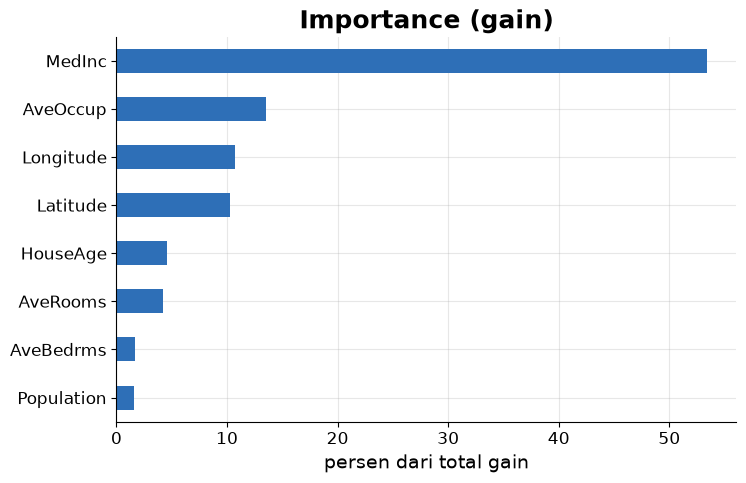

In [5]:
gain = pd.Series(model.booster_.feature_importance("gain"), index=X.columns)
gain = gain.sort_values()
gain_percent = gain / gain.sum() * 100
gain_percent.plot.barh(color=BLUE)
plt.title("Importance (gain)")
plt.xlabel("persen dari total gain")
plt.savefig("jelas_importance_gain.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Permutation importance
**Kapan dipakai:** ukuran importance yang jujur terhadap data validasi untuk model apa pun.
**Cara baca:** bar = penurunan skor R2 bila kolom itu diacak, garis hitam = variasi antar
ulangan. Mendekati nol atau negatif = fitur tidak membantu.

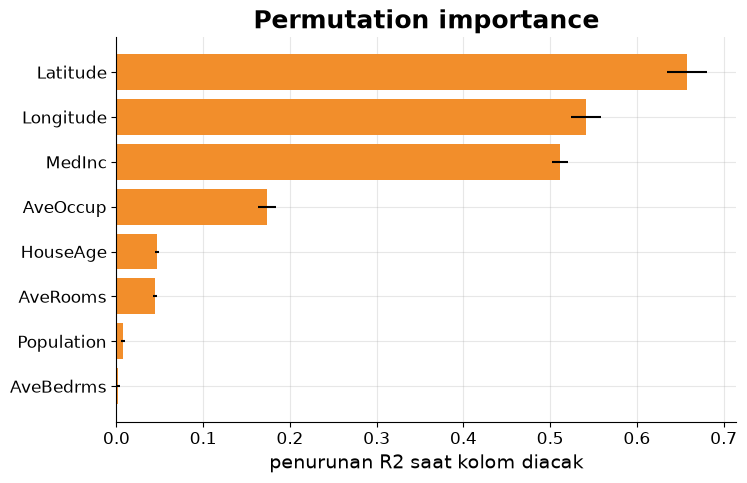

In [6]:
result = permutation_importance(model, X_val, y_val, n_repeats=10, random_state=SEED, n_jobs=1)
permutation = pd.Series(result.importances_mean, index=X.columns)
permutation_std = pd.Series(result.importances_std, index=X.columns)
order = permutation.sort_values().index
plt.barh(order, permutation[order], xerr=permutation_std[order], color=ORANGE)
plt.title("Permutation importance")
plt.xlabel("penurunan R2 saat kolom diacak")
plt.savefig("jelas_permutation.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. SHAP summary (beeswarm)
**Kapan dipakai:** grafik penjelasan paling informatif: arah DAN besar pengaruh fitur.
**Cara baca:** tiap titik = satu baris data. Posisi kanan = mendorong prediksi naik, kiri =
turun. Warna merah = nilai fitur tinggi. Contoh: MedInc merah di kanan = pendapatan tinggi
menaikkan harga.

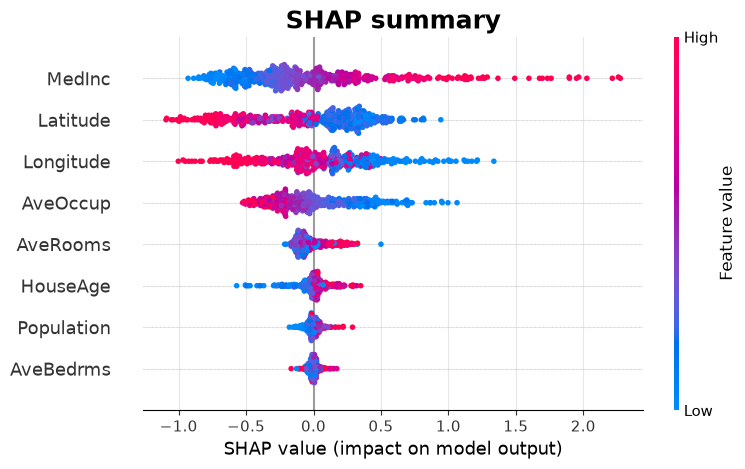

In [7]:
shap.summary_plot(shap_values, show=False)
plt.title("SHAP summary")
plt.savefig("jelas_shap_summary.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. SHAP bar (rata-rata pengaruh mutlak)
**Kapan dipakai:** slide ringkas untuk non-teknis: "fitur terpenting".
**Cara baca:** panjang bar = rata-rata besarnya pengaruh fitur terhadap prediksi (satuan
sama dengan target).

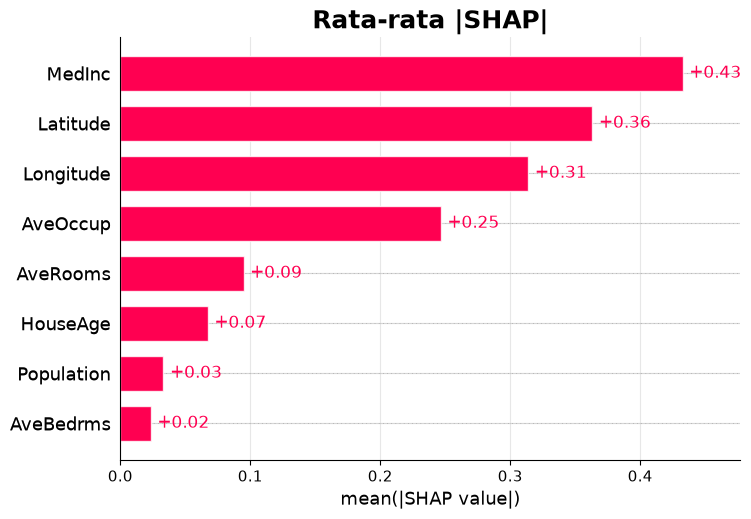

In [8]:
shap.plots.bar(shap_values, show=False)
plt.title("Rata-rata |SHAP|")
plt.savefig("jelas_shap_bar.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. SHAP dependence
**Kapan dipakai:** ingin tahu bentuk pengaruh satu fitur (naik terus? jenuh? U?) dan interaksinya.
**Cara baca:** sumbu x = nilai fitur, sumbu y = pengaruhnya pada prediksi, warna = fitur lain
yang paling berinteraksi. Sebaran vertikal pada x yang sama = ada interaksi.

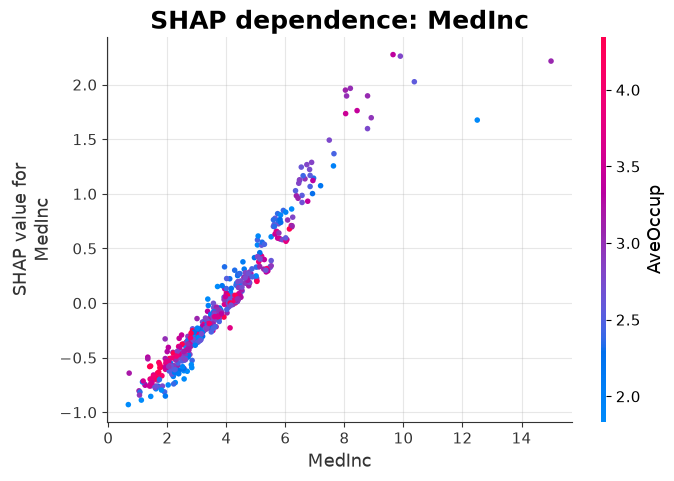

In [9]:
shap.dependence_plot(MAIN_FEATURE, shap_values.values, sample, show=False)
plt.title(f"SHAP dependence: {MAIN_FEATURE}")
plt.savefig("jelas_shap_dependence.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. SHAP waterfall (menjelaskan satu prediksi)
**Kapan dipakai:** menjawab "kenapa baris/pelanggan ini diprediksi segitu?" untuk contoh kasus
di presentasi. **Cara baca:** mulai dari nilai dasar E[f(x)] (kiri-bawah), tiap bar menambah
(merah) atau mengurangi (biru) prediksi sampai ke hasil akhir f(x) di atas.

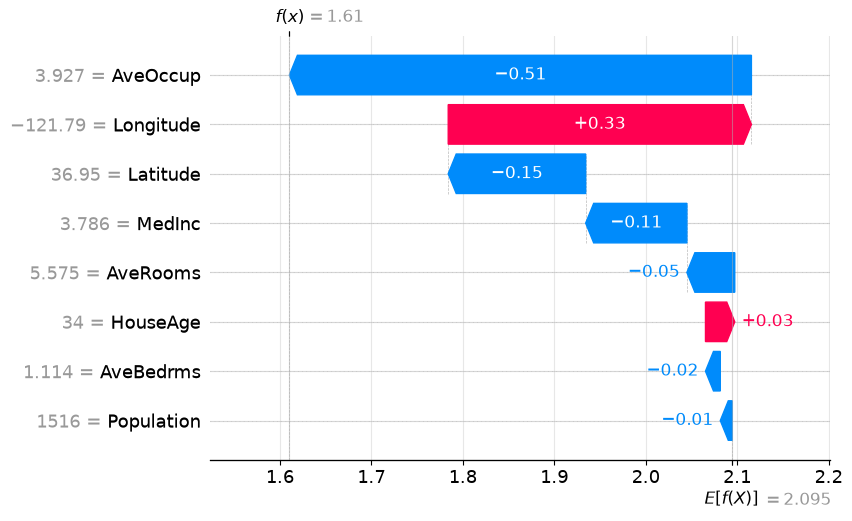

In [10]:
shap.plots.waterfall(shap_values[EXPLAINED_ROW], show=False)
plt.savefig("jelas_shap_waterfall.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. PDP + ICE
**Kapan dipakai:** efek rata-rata satu fitur terhadap prediksi dengan fitur lain dibiarkan
apa adanya. **Cara baca:** garis tebal = PDP (rata-rata), garis tipis = ICE (satu garis per
baris). Kalau garis tipis menyebar tidak sejajar = ada interaksi, PDP saja menutupi itu.

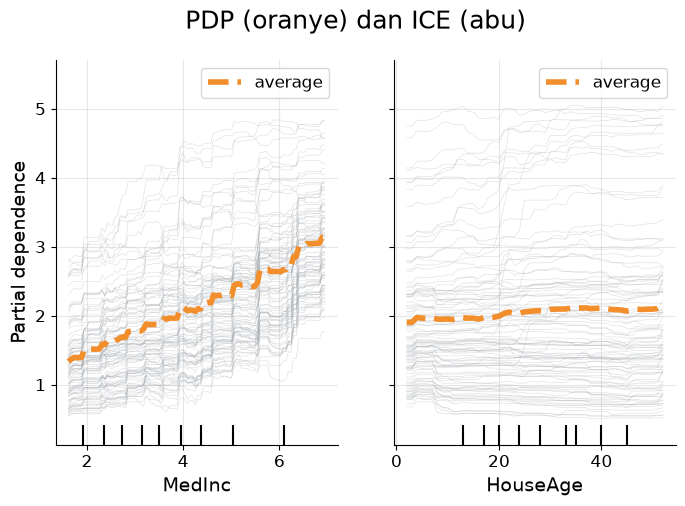

In [11]:
PartialDependenceDisplay.from_estimator(model, X_val, [MAIN_FEATURE, "HouseAge"], kind="both",
                                        subsample=100, random_state=SEED,
                                        ice_lines_kw={"color": GREY, "alpha": 0.3},
                                        pd_line_kw={"color": ORANGE, "linewidth": 4})
plt.gcf().suptitle("PDP (oranye) dan ICE (abu)", fontsize=18)
# Alternatif peta panas dua fitur: from_estimator(model, X_val, [(MAIN_FEATURE, "HouseAge")])
plt.savefig("jelas_pdp_ice.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Apakah tiga metode sepakat?
**Kapan dipakai:** sebelum menyimpulkan "fitur X terpenting" di laporan, cek konsistensi.
**Cara baca:** angka = peringkat (1 = terpenting) tiap metode. Kolom yang peringkatnya mirip =
kesimpulan kuat. Yang berbeda jauh = selidiki (korelasi antar fitur, kebocoran).

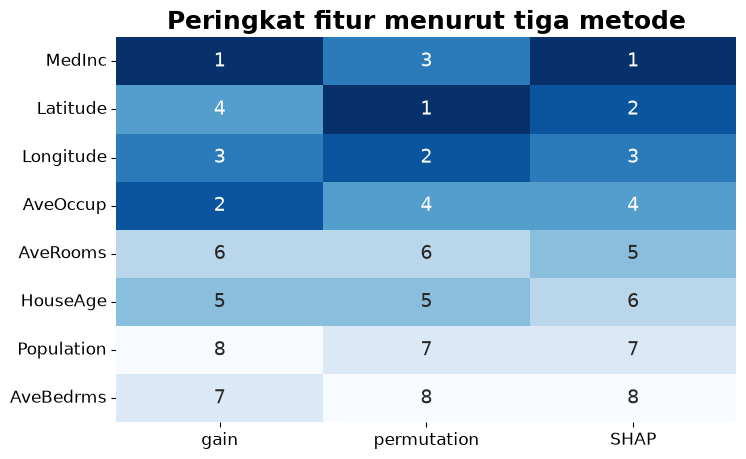

In [12]:
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
ranks = pd.DataFrame(index=X.columns)
ranks["gain"] = gain
ranks["permutation"] = permutation
ranks["SHAP"] = mean_abs_shap
ranks = ranks.rank(ascending=False).astype(int)
ranks = ranks.sort_values("SHAP")
sns.heatmap(ranks, annot=True, fmt="d", cmap="Blues_r", cbar=False)
plt.title("Peringkat fitur menurut tiga metode")
plt.ylabel("")
plt.grid(False)
plt.savefig("jelas_bandingkan_metode.png", dpi=200, bbox_inches="tight")
plt.show()